# Stress-Predict Dataset Assignment
**Name:** Jack Hickey <br>
**Class:** 1MOA2 <br>
**Student ID:** 26257770

## 1. Environment Setup

To ensure this works the following packages are required:
* pandas
* scikit-learn
* matplotlib
* seaborn

In [1]:
#Data manipulation and timing
import pandas as pd
import time

# Pre-processing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

# Machine Learning Algorithms
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# Evaluation Metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Data Visualisation
import matplotlib.pyplot as plt
import seaborn as sns


## Exploratory Data Analysis

In [ ]:
# Load the data
data = pd.read_csv("../data/Data.csv")

data.head()

,Participant,HR,respr,Time(sec),Label
0,2,118.00,12.127693,1644227583,0
1,2,113.50,12.127693,1644227584,0
2,2,93.00,12.127693,1644227585,0
3,2,93.25,12.127693,1644227586,0
4,2,86.40,12.127693,1644227587,0


In [3]:
data.describe()

,Participant,HR,respr,Time(sec),Label
count,112516.000000,112472.000000,112516.000000,1.125160e+05,112516.000000
mean,18.475470,80.216177,12.465482,1.645692e+09,0.327198
std,9.871133,12.732206,2.030810,8.179419e+05,0.469192
min,2.000000,49.000000,5.204728,1.644228e+09,0.000000
25%,10.000000,71.330000,11.191843,1.644846e+09,0.000000
50%,18.000000,77.890000,12.743635,1.645461e+09,0.000000
75%,27.000000,87.020000,13.877519,1.646648e+09,1.000000
max,35.000000,146.780000,18.163532,1.646842e+09,1.000000


In [4]:
data['Label'].value_counts(normalize=True) * 100

Label
0    67.280209
1    32.719791
Name: proportion, dtype: float64

/var/folders/3y/9d8pd9rd64z5xqr5f08z5j240000gn/T/ipykernel_11761/3814453722.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data, x='Label', palette='viridis')


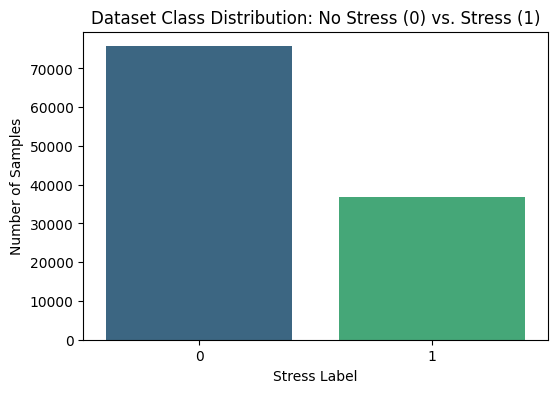

In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(data=data, x='Label', palette='viridis')
plt.title('Dataset Class Distribution: No Stress (0) vs. Stress (1)')
plt.xlabel('Stress Label')
plt.ylabel('Number of Samples')
plt.show()

The dataset exhibits a significant class imbalance, with label `0` (No Stress) accounting for approximately `67%` of the samples. This establishes a majority-class baseline of `67%`. This means a naive model predicting only the majority class would achieve this accuracy by default. Consequently, model performance must be evaluated using metrics robust to imbalance, such as the F1 Score.

In [6]:
# Find missing values
data.isna().sum()

Participant     0
HR             44
respr           0
Time(sec)       0
Label           0
dtype: int64

In [8]:
participants = data['Participant'].unique()
print(f"Partipants: {participants}")

Partipants: [ 2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25
 26 27 28 29 30 31 32 33 34 35]


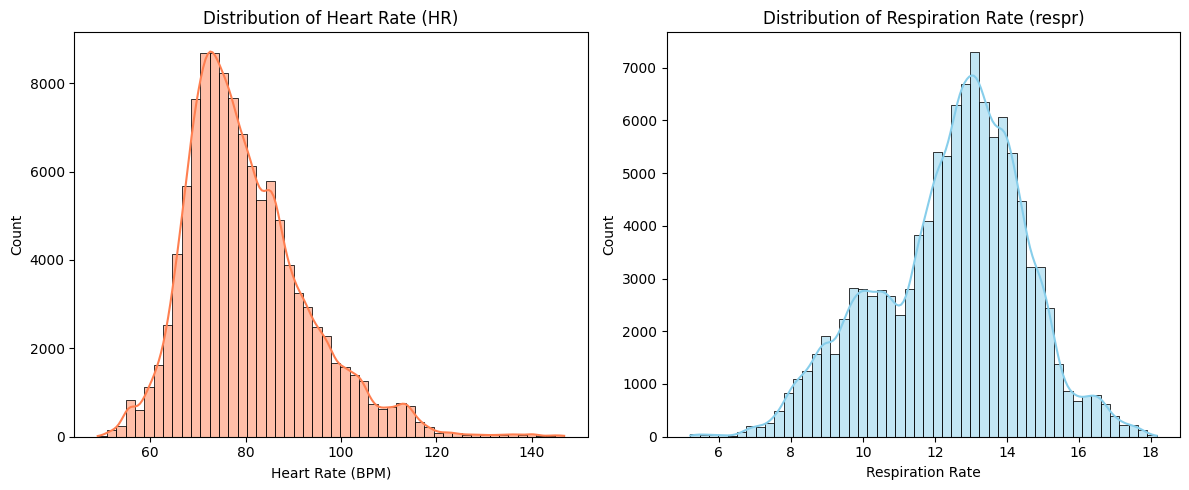

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(data=data, x='HR', bins=50, kde=True, ax=axes[0], color='coral')
axes[0].set_title('Distribution of Heart Rate (HR)')
axes[0].set_xlabel('Heart Rate (BPM)')

sns.histplot(data=data, x='respr', bins=50, kde=True, ax=axes[1], color='skyblue')
axes[1].set_title('Distribution of Respiration Rate (respr)')
axes[1].set_xlabel('Respiration Rate')

plt.tight_layout()
plt.show()

The heart rate data clearly shows a right skewed distribution while the respiration data is roughly bell shaped overall with some occasional bumps. 
The variety of values in heart rate could potential distort our models and favour the large range in heart rate data over respiration meaning applying normalisation to this data will be very important for KNN.

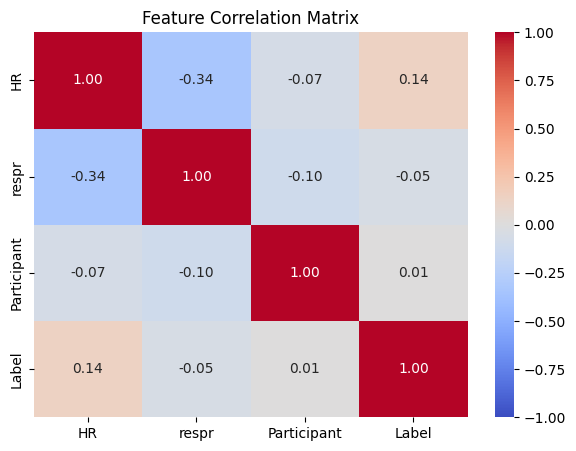

In [10]:
plt.figure(figsize=(7, 5))

# Isolate relevant columns to prevent noise from IDs or Timestamps
features_to_correlate = data[['HR', 'respr', 'Participant', 'Label']]
corr_matrix = features_to_correlate.corr()

# fmt=".2f" ensures correlations are readable to two decimal places
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Feature Correlation Matrix')
plt.show()

The correlation matrix is very interesting and shows a potential challenge for getting meaningful results from the data. This matrix interestingly shows there is only a slight correlation between an increated heart rate and stress `(0.14)`. What's even more interesting is there tends to be a very slight decline in a participants respiration rate as their heart rate goes up `(-0.34)`. This is the inverse of what I would expect to see. There is also nearly zero `(-0.05)` correlation between respiration and stress. 

Keeping both of these in will not be feeding the algorithm redundant information and it will need both of these values to be able to get the full picture. 

Participant overall has a very weak correlation to any of the features but even leaving participant in the dataset could run the risk of the algorithm correlating a particular state with a particular participant. 

It is worth noting that physiological data could present some lags in how the data is captured. Wrist based heart rate sensors are generally considered slow at picking up sudden changes in heart rate. If respiration is captured through another method the timing between these two may not correlate.

## Data Pre-Processing

Examination of the dataset reveals 44 missing values within the Heart Rate (`HR`) column. While mean or median imputation is a common strategy, injecting static values into continuous physiological time-series data creates artificial flatlines. Distance-based algorithms (like KNN) and threshold-based algorithms (like Decision Trees) can misinterpret these artifacts. Given that 44 rows constitute a negligible fraction of the 112,516 total entries, dropping these rows entirely is the safest approach to maintain data integrity.

In [11]:

# Drop any rows that contain a null value
# In the analysis of the data it was identified that 44 HRs were null
data = data.dropna(how='any', axis=0)
data.isna().sum()

Participant    0
HR             0
respr          0
Time(sec)      0
Label          0
dtype: int64

To prevent data leakage caused by correlating sequential time-series entries from the same individual, the train/test split is performed at the participant level rather than through naive row shuffling. Applying an 80/20 subject split allocates 27 participants to the training set and 7 participants to the test set.

In [12]:

train_ids, test_ids = train_test_split(participants, test_size=0.20, random_state=42)
train_df = data[data['Participant'].isin(train_ids)]
test_df = data[data['Participant'].isin(test_ids)]

train_participants = train_df['Participant'].unique()
print(f"Training Participants: {train_participants}")


Training Participants: [ 2  3  4  5  6  7  8  9 11 12 13 14 15 16 18 19 20 22 24 25 27 30 31 32
 33 34 35]


In [13]:
test_participants = test_df['Participant'].unique()
print(f"Testing Participants: {test_participants}")

Testing Participants: [10 17 21 23 26 28 29]


The `Participant` and `Time(sec)` columns are removed from the training and test data. The `Participant` column risks the algorithm associating a particular particpants ID with a stress state. The `Time(sec)` column is dropped as it simply serves as an index and provides no predictive value for a standard classification algorithm. 

In [14]:
train_df = train_df.drop(columns=['Participant', 'Time(sec)'])
test_df = test_df.drop(columns=['Participant', 'Time(sec)'])

Split the data into `X_featureSet` which is the input data (`HR`, `respr`) and `y_featureSet` (`Label`)

In [15]:
y_train = train_df['Label']
X_train = train_df.drop(columns=['Label'])

y_test = test_df['Label']
X_test = test_df.drop(columns=['Label'])

Dimension rescaling is essential for $k$-NN as identified in the exploratory analysis phase. If we were to keep `HR` and `respr` there is a chance that `HR` given it's much greater range of values would dominate the dataset. The two methods applied here are Z-Distance and 0-1 Normalisation (Range Normalisation).

In [16]:
std_scaler = StandardScaler() # Z-Normalisation
min_max_scaler = MinMaxScaler() # Range Normalisation

std_scaler.fit(X_train)
X_train_std = std_scaler.transform(X_train)
X_test_std = std_scaler.transform(X_test)

min_max_scaler.fit(X_train)
X_train_minmax = min_max_scaler.transform(X_train)
X_test_minmax = min_max_scaler.transform(X_test)

## Algorithm Selection
The algorithms selected for comparison are Decision Trees and $k$-Nearest Neighbours ($k$-NN), allowing us to evaluate variations of two fundamentally different machine learning paradigms [1](#ref1) [2](#ref2). Decision Trees represent eager learning, where the algorithm induces an explicit, generalised hypothesis (hierarchical decision boundaries) from the training data prior to receiving unseen queries [1](#ref1) [3](#ref3). Conversely, $k$-NN represents lazy (instance-based) learning, deferring model evaluation until testing time by storing training examples as vectors in a multidimensional feature space and classifying query instances based on proximity to their nearest neighbours [2](#ref1) [4](#ref3).

To ensure a robust comparative analysis, each algorithm is evaluated against key internal variations. Decision Trees are evaluated using both Shannon Entropy and the Gini Impurity Index [1](#ref1) [3](#ref3). $k$-NN is evaluated across multiple neighbourhood sizes ($k$) and multiple distance metrics, the primary ones being Euclidean distance ($L_2$ norm) and Manhattan distance ($L_1$ norm) [2](#ref2) [4](#ref4).This setup allows us to systematically evaluate how structural hypothesis choices and distance geometry impact classification performance on this dataset [1](#ref1) [2](#ref2).

## Model Evaluation

To capture the models suitability I will use several metrics.

* Accuracy: This is the percentage of predictions that the model got right.
* Precision Score: Out of the times the model predicts stressed how many times it was right.
* Recall: How many of the actual stress events in the dataset does the model successfully catch.
* F1 Score: The mean of Precision and Recall given a more balanced answer when dealing with imbalanced datasets.
* Time: It may be of importance to see how long a model takes to run.

In [17]:
def evaluate_model(model, model_name, X_train_data, y_train_data, X_test_data, y_test_data):
    # Time the model
    start_time = time.time()

    # Train the model
    model.fit(X_train_data, y_train_data)

    # Predict
    y_prediction = model.predict(X_test_data)

    # Calculate time
    end_time = time.time()
    elapsed_time = end_time - start_time

    # Calculate Metrics
    acc = accuracy_score(y_test_data, y_prediction)
    prec = precision_score(y_test_data, y_prediction)
    rec = recall_score(y_test_data, y_prediction)
    f1 = f1_score(y_test_data, y_prediction)

    return {
        "Model": model_name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1 Score": f1,
        "Execution Time (s)": elapsed_time
    }

### KNN

In [18]:
def knn_evaluate(model_details, num_neighbours=[1, 5, 15, 30, 50, 100], distance=[1, 2, 4],
                  X_train=X_train_std, X_test=X_test_std, weight='uniform'):
    knn_results_list = []

    for k in num_neighbours:
        for p in distance:
            knn_model_name = f"{model_details}: (p={p}, k={k})"
            knn_model = KNeighborsClassifier(n_neighbors=k, p=p, weights=weight)
            res = evaluate_model(knn_model, knn_model_name, X_train, y_train, X_test, y_test)
            res['K Neighbours'] = k
            res['Distance P'] = p
            knn_results_list.append(res)
    return knn_results_list


In [19]:
z_normalised_knn_results_list = knn_evaluate("Z-Normalised")

print("EVALUATING KNN Z-NORMALISED DATA")
z_normalised_knn_results_df = pd.DataFrame(z_normalised_knn_results_list)

display(z_normalised_knn_results_df.sort_values(by='Accuracy', ascending=False)[
    ['Model', 'K Neighbours', 'Distance P','Accuracy', 'Precision', 'Recall', 'F1 Score']
])


EVALUATING KNN Z-NORMALISED DATA


,Model,K Neighbours,Distance P,Accuracy,Precision,Recall,F1 Score
15,"Z-Normalised: (p=1, k=100)",100,1,0.607452,0.366209,0.225926,0.279450
17,"Z-Normalised: (p=4, k=100)",100,4,0.606382,0.364911,0.227249,0.280078
16,"Z-Normalised: (p=2, k=100)",100,2,0.605090,0.363139,0.228307,0.280354
12,"Z-Normalised: (p=1, k=50)",50,1,0.597469,0.358516,0.246693,0.292274
14,"Z-Normalised: (p=4, k=50)",50,4,0.595508,0.357358,0.251190,0.295013
10,"Z-Normalised: (p=2, k=30)",30,2,0.595374,0.359948,0.258201,0.300701
13,"Z-Normalised: (p=2, k=50)",50,2,0.595240,0.355926,0.248677,0.292789
11,"Z-Normalised: (p=4, k=30)",30,4,0.594215,0.356652,0.254233,0.296857
9,"Z-Normalised: (p=1, k=30)",30,1,0.594215,0.357235,0.255688,0.298049
7,"Z-Normalised: (p=2, k=15)",15,2,0.580132,0.349312,0.285317,0.314088


The above has been arranged by accuracy but accuracy is only some of the picture. We must remember that our dataset is imbalanced and this is shown in the data above through the almost direct correlation between the accuracy decreasing and the F1 Score increasing. This clearly shows that the imbalance in our dataset is playing a role in the predictive outcome of the algorithm.

In [20]:
def knn_display_accuracy(knn_df, title="KNN Accuracy vs. k-value"):
    # 1. Metric mapping dictionary
    metric_map = {
        1: "Manhattan (p=1)",
        2: "Euclidean (p=2)",
        4: "Minkowski (p=4)"
    }
    
    df = knn_df.copy()
    df['Distance (p)'] = df['Model'].str.extract(r'p=(\d+)').astype(int)
    df['k'] = df['Model'].str.extract(r'k=(\d+)').astype(int)
    
    # 3. Pivot data dynamically
    pivot_acc = df.pivot(index='k', columns='Distance (p)', values='Accuracy')
    
    # 4. Safely rename columns using the mapping dictionary
    pivot_acc = pivot_acc.rename(columns=lambda p: metric_map.get(p, f"Order of {p}"))
    
    # 5. Plot
    ax = pivot_acc.plot(kind='line', marker='o', figsize=(9, 5))
    plt.title(title)
    plt.xlabel("Number of Neighbours (k)")
    plt.ylabel("Accuracy")
    
    # Dynamically set X-ticks to the exact k-values tested
    plt.xticks(sorted(df['k'].unique()))
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(title="Distance Metric", bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

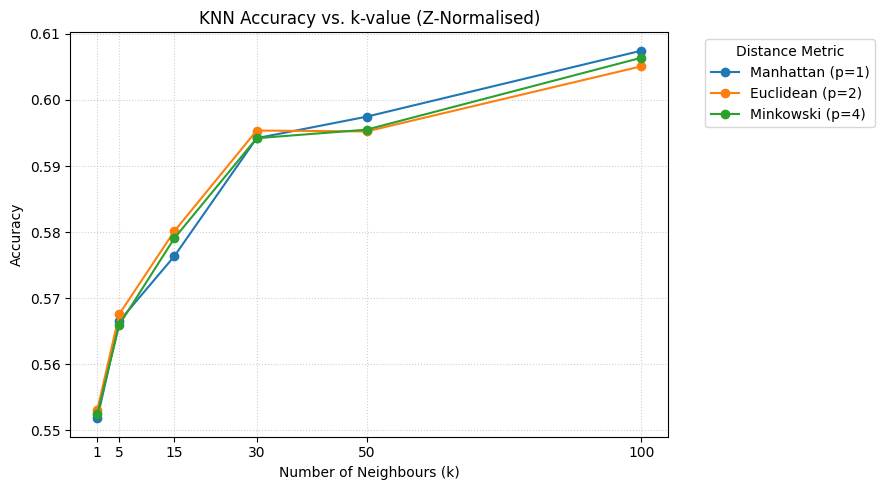

In [21]:
knn_display_accuracy(z_normalised_knn_results_df, "KNN Accuracy vs. k-value (Z-Normalised)")

In [22]:
range_normalised_knn_results_list = knn_evaluate(model_details="Range-Normalised", X_train=X_train_minmax, X_test=X_test_minmax)

print("EVALUATING KNN RANGE-NORMALISED DATA")
range_normalised_knn_results_df = pd.DataFrame(range_normalised_knn_results_list)

display(range_normalised_knn_results_df.sort_values(by='Accuracy', ascending=False)[
    ['Model', 'K Neighbours', 'Distance P','Accuracy', 'Precision', 'Recall', 'F1 Score']
])

EVALUATING KNN RANGE-NORMALISED DATA


,Model,K Neighbours,Distance P,Accuracy,Precision,Recall,F1 Score
15,"Range-Normalised: (p=1, k=100)",100,1,0.606337,0.364833,0.227249,0.280055
16,"Range-Normalised: (p=2, k=100)",100,2,0.605535,0.364362,0.229365,0.281516
17,"Range-Normalised: (p=4, k=100)",100,4,0.605268,0.363617,0.228704,0.280796
14,"Range-Normalised: (p=4, k=50)",50,4,0.596444,0.358882,0.251455,0.295714
12,"Range-Normalised: (p=1, k=50)",50,1,0.596176,0.356474,0.246561,0.291501
13,"Range-Normalised: (p=2, k=50)",50,2,0.595508,0.356112,0.248148,0.292485
10,"Range-Normalised: (p=2, k=30)",30,2,0.594215,0.357393,0.256085,0.298374
9,"Range-Normalised: (p=1, k=30)",30,1,0.593547,0.355823,0.254630,0.296839
11,"Range-Normalised: (p=4, k=30)",30,4,0.592210,0.353050,0.252646,0.294526
7,"Range-Normalised: (p=2, k=15)",15,2,0.579820,0.348179,0.283333,0.312427


Comparing the results of the `Range-Normalised` data with `Z-Normalised` there is very little difference in the results. Both display the same paradox where as the accuracy decreases the F1-Score increases. This also tracks with the value of $k$ whereby when $k$ is higher it outputs a higher accuracy in favour of the dominant class but a lower F1 score. 

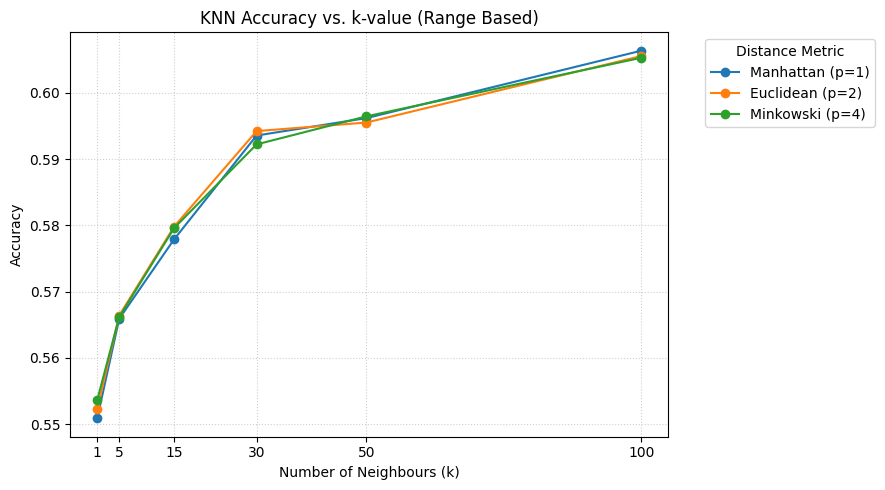

In [23]:
knn_display_accuracy(range_normalised_knn_results_df, "KNN Accuracy vs. k-value (Range Based)")

In [24]:
def knn_display_f1(df1, df2, title="KNN F1 Score Comparison", label1="Dataset 1", label2="Dataset 2"):
    """
    Plots a dual-series validation curve for KNN F1 scores across varying k and distance metrics.
    Automatically extracts 'k' and 'Distance (p)' if not already present.
    """
    metric_map = {
        1: "Manhattan",
        2: "Euclidean",
        3: "Order of 3"
    }

    def _prepare_df(raw_df):
        df_copy = raw_df.copy()
        if 'Distance (p)' not in df_copy.columns:
            df_copy['Distance (p)'] = df_copy['Model'].str.extract(r'p=(\d+)').astype(int)
        if 'k' not in df_copy.columns:
            df_copy['k'] = df_copy['Model'].str.extract(r'k=(\d+)').astype(int)
        return df_copy

    # 1. Prepare isolated copies containing 'k' and 'Distance (p)'
    d1 = _prepare_df(df1)
    d2 = _prepare_df(df2)

    # 2. Pivot the prepared copies (d1, d2)
    pivot1 = d1.pivot(index='k', columns='Distance (p)', values='F1 Score')
    pivot2 = d2.pivot(index='k', columns='Distance (p)', values='F1 Score')

    # 3. Rename columns dynamically using label prefixes
    pivot1 = pivot1.rename(columns=lambda p: f"{label1} ({metric_map.get(p, f'p={p}')})")
    pivot2 = pivot2.rename(columns=lambda p: f"{label2} ({metric_map.get(p, f'p={p}')})")

    # 4. Render dual lines on a shared canvas
    ax = pivot1.plot(kind='line', marker='o', figsize=(10, 6))
    pivot2.plot(kind='line', marker='X', linestyle='--', ax=ax)

    # 5. Styling and dynamic ticks sourced from d1 and d2
    plt.title(title)
    plt.xlabel("Number of Neighbours (k)")
    plt.ylabel("F1 Score")

    all_k = sorted(set(d1['k'].dropna()).union(set(d2['k'].dropna())))
    plt.xticks(all_k)
    plt.grid(True, linestyle=':', alpha=0.7)

    # 6. Extract handles/labels and format legend
    handles, labels = ax.get_legend_handles_labels()
    plt.legend(handles, labels, bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

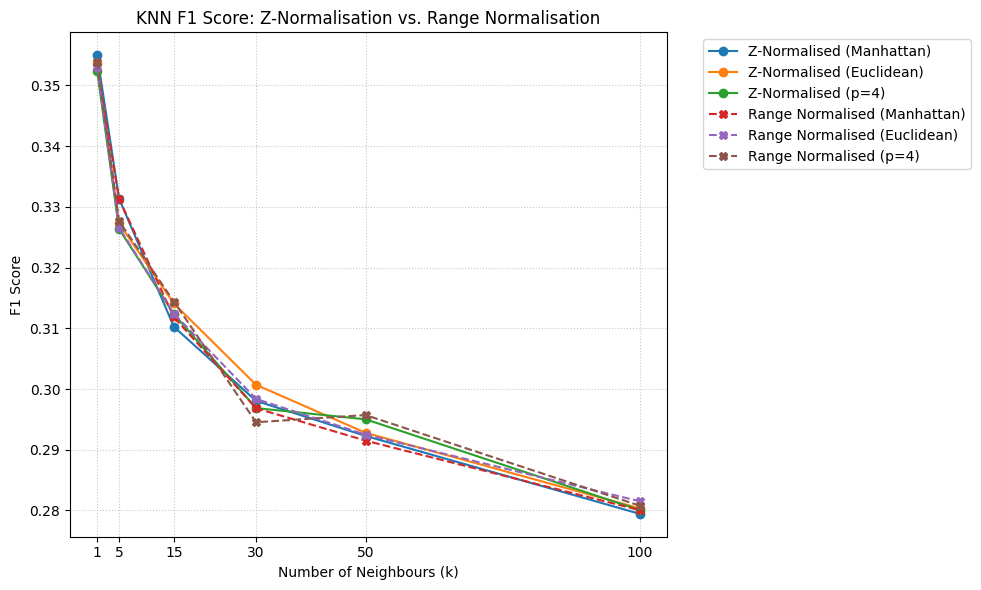

In [25]:
knn_display_f1(
    z_normalised_knn_results_df, 
    range_normalised_knn_results_df, 
    "KNN F1 Score: Z-Normalisation vs. Range Normalisation", 
    "Z-Normalised", 
    "Range Normalised"
)

The above visualisation exposes the classic accuracy paradox caused by the dataset's underlying class imbalance (67.28% Class 0 vs. 32.71% Class 1). While the accuracy graph implies improved performance as $k$ increases the degrading F1 Score reveals that the model is simply defaulting to the majority class. As the neighbourhood size expands, the minority class is outvoted, rendering the model ineffective for actual stress detection. To mitigate this majority bias and improve minority class recognition, I will use a distance-weighted voting mechanism and examine the impact of this.

In [26]:
print("EVALUATING WEIGHTED KNN Z-NORMALISED DATA")

z_normalised_weighted_knn_results_list = knn_evaluate(model_details="Z-Distance", weight='distance')
z_normalised_weighted_knn_results_df = pd.DataFrame(z_normalised_weighted_knn_results_list)

display(z_normalised_weighted_knn_results_df.sort_values(by='Accuracy', ascending=False)[
    ['Model', 'K Neighbours', 'Distance P','Accuracy', 'Precision', 'Recall', 'F1 Score']
])

EVALUATING WEIGHTED KNN Z-NORMALISED DATA


,Model,K Neighbours,Distance P,Accuracy,Precision,Recall,F1 Score
15,"Z-Distance: (p=1, k=100)",100,1,0.595909,0.358018,0.251323,0.295329
17,"Z-Distance: (p=4, k=100)",100,4,0.594349,0.355672,0.251323,0.294528
16,"Z-Distance: (p=2, k=100)",100,2,0.593859,0.354670,0.250661,0.293730
14,"Z-Distance: (p=4, k=50)",50,4,0.586460,0.351682,0.269577,0.305204
13,"Z-Distance: (p=2, k=50)",50,2,0.585837,0.350886,0.269709,0.304988
12,"Z-Distance: (p=1, k=50)",50,1,0.584722,0.349641,0.270370,0.304938
10,"Z-Distance: (p=2, k=30)",30,2,0.582316,0.351524,0.283730,0.314010
9,"Z-Distance: (p=1, k=30)",30,1,0.581424,0.350376,0.283730,0.313551
11,"Z-Distance: (p=4, k=30)",30,4,0.580800,0.348788,0.281614,0.311622
8,"Z-Distance: (p=4, k=15)",15,4,0.577592,0.351041,0.298942,0.322903


In [27]:
print("EVALUATING WEIGHTED KNN RANGE-NORMALISED DATA")

range_normalised_weighted_knn_results_list = knn_evaluate(model_details="Range-Normalised", X_train=X_train_minmax, X_test=X_test_minmax, weight='distance')
range_normalised_weighted_knn_results_df = pd.DataFrame(range_normalised_weighted_knn_results_list)

display(range_normalised_weighted_knn_results_df.sort_values(by='Accuracy', ascending=False)[
    ['Model', 'K Neighbours', 'Distance P','Accuracy', 'Precision', 'Recall', 'F1 Score']
])

EVALUATING WEIGHTED KNN RANGE-NORMALISED DATA


,Model,K Neighbours,Distance P,Accuracy,Precision,Recall,F1 Score
15,"Range-Normalised: (p=1, k=100)",100,1,0.596756,0.359623,0.252116,0.296423
17,"Range-Normalised: (p=4, k=100)",100,4,0.595775,0.358029,0.251852,0.295698
16,"Range-Normalised: (p=2, k=100)",100,2,0.595017,0.356404,0.250661,0.294323
13,"Range-Normalised: (p=2, k=50)",50,2,0.587664,0.353430,0.269841,0.306031
14,"Range-Normalised: (p=4, k=50)",50,4,0.586862,0.351768,0.268386,0.304472
12,"Range-Normalised: (p=1, k=50)",50,1,0.585435,0.349983,0.268783,0.304055
10,"Range-Normalised: (p=2, k=30)",30,2,0.582360,0.351240,0.282804,0.313329
11,"Range-Normalised: (p=4, k=30)",30,4,0.582182,0.350716,0.282011,0.312633
9,"Range-Normalised: (p=1, k=30)",30,1,0.581870,0.351870,0.286243,0.315682
8,"Range-Normalised: (p=4, k=15)",15,4,0.576700,0.349487,0.297619,0.321474


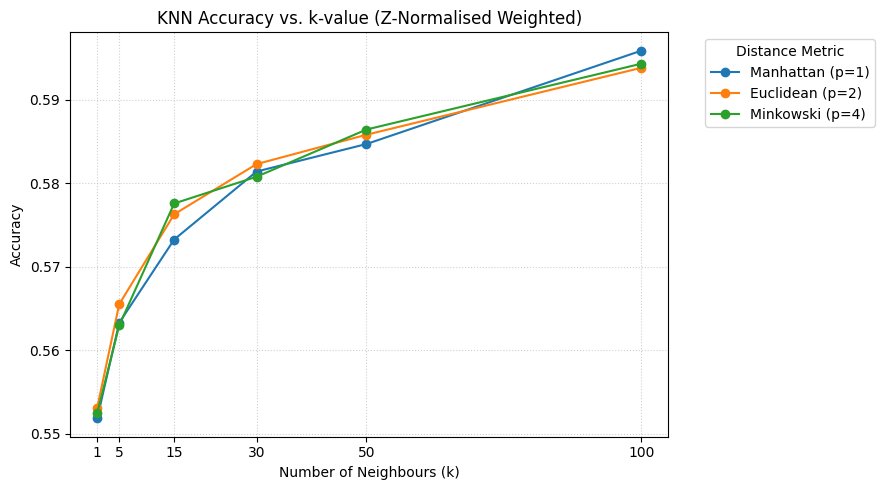

In [28]:
knn_display_accuracy(z_normalised_weighted_knn_results_df, "KNN Accuracy vs. k-value (Z-Normalised Weighted)")

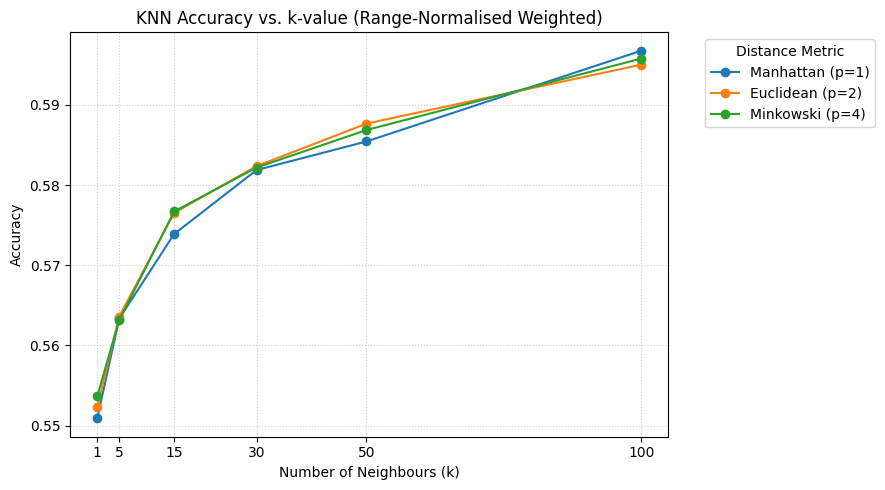

In [29]:
knn_display_accuracy(range_normalised_weighted_knn_results_df, "KNN Accuracy vs. k-value (Range-Normalised Weighted)")

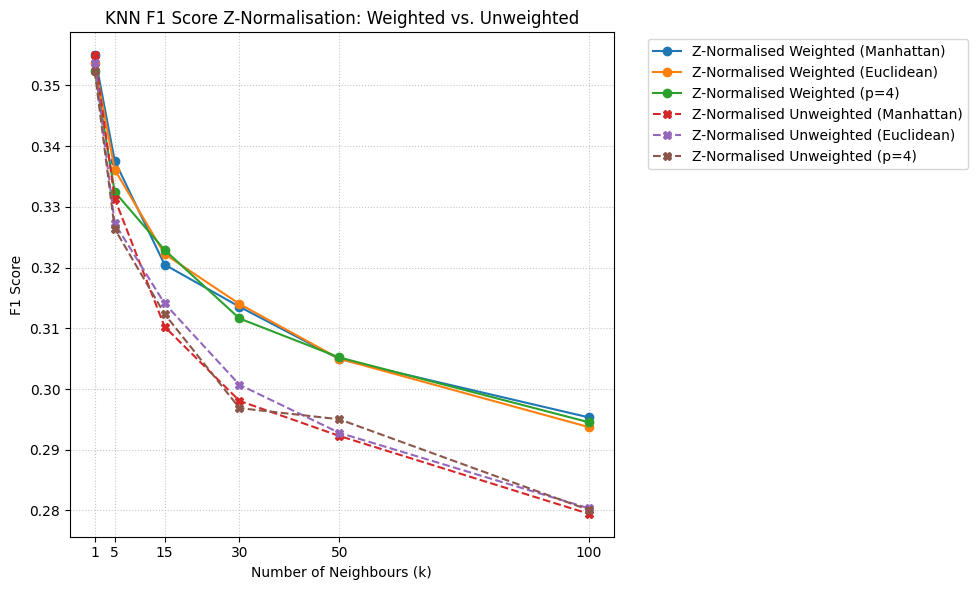

In [30]:
knn_display_f1(z_normalised_weighted_knn_results_df, z_normalised_knn_results_df, "KNN F1 Score Z-Normalisation: Weighted vs. Unweighted", "Z-Normalised Weighted", "Z-Normalised Unweighted")

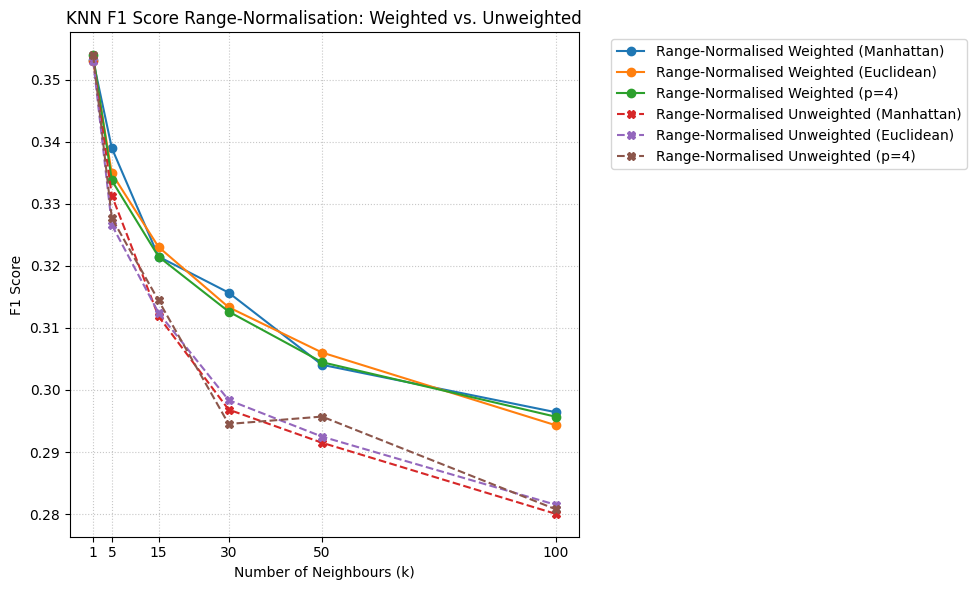

In [31]:
knn_display_f1(range_normalised_weighted_knn_results_df, range_normalised_knn_results_df, "KNN F1 Score Range-Normalisation: Weighted vs. Unweighted", "Range-Normalised Weighted", "Range-Normalised Unweighted")

These graphs reveal that using a weighted method maintained accuracy and also slightly improved the output of using weighted voting as $k$ increases. The F1 Score still remains low and for calculating stress in patients this method would not be suitable. 

What has happened is instead of improving the accuracy with increasing the number of K the algorithm is just defaulting to the average class more and more which is visible by the sharp decline in the F1 Score. This a direct result of the dominating class which is 0. 

### Decision Trees

In [32]:
# Decision Trees
dt_results_list = []
print("EVALUATING DECISION TREE")
# for model_name, model in dt_models.items():
#     dt_results_list.append(evaluate_model(model, model_name, X_train, y_train, X_test, y_test))
for crit in ['gini', 'entropy']:
        model_name = f"DT_{crit}"
        model = DecisionTreeClassifier(criterion=crit, random_state=42)
        
        # Evaluate model using your existing pipeline
        res = evaluate_model(model, model_name, X_train, y_train, X_test, y_test)
        res['criterion'] = crit
        dt_results_list.append(res)

dt_results_df = pd.DataFrame(dt_results_list)

display(dt_results_df[['Model', 'criterion', 'Accuracy', 'Precision', 'Recall', 'F1 Score']])

EVALUATING DECISION TREE


,Model,criterion,Accuracy,Precision,Recall,F1 Score
0,DT_gini,gini,0.544924,0.334623,0.354762,0.344398
1,DT_entropy,entropy,0.547375,0.338114,0.358598,0.348055


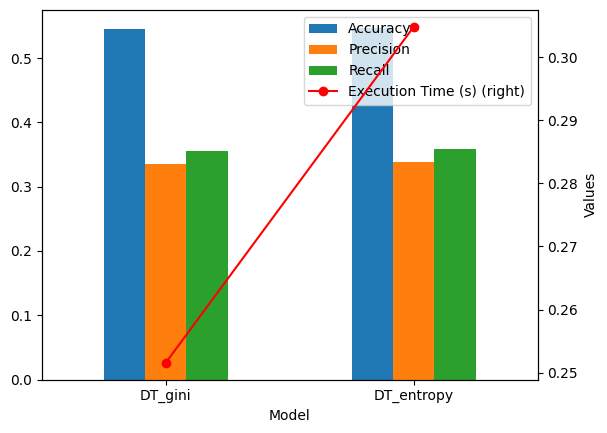

In [33]:
ax = dt_results_df.plot(x="Model", y=["Accuracy", "Precision", "Recall"], kind="bar")

dt_results_df.plot(x="Model", y="Execution Time (s)", kind="line", color="red", marker='o', ax=ax, secondary_y=True)
plt.ylabel("Values")
plt.show()

Examing the difference between Entropy or the Gini index shows there is not much impact on the accuracy of our decision tree which sits at about 54% for both of them. This is close to the majority class which is 0 at 67% and the F1 Score reveals this to be a deciding factor. 

To address some issues we will attempt to apply pruning starting with `max_depth` as the physiological data contains thousands of rows which could be creating hyper-specifc sceanarios.

`max_depth` as the name implies prevents the tree from growing beyond a set threshold. This may have a further negative impact on F1 score however as the most dominant class could win out. 

In [34]:
depth_range = [1, 2, 3, 4, 5, 7, 10, 15, 20, None]
dt_depth_results = []

for d in depth_range:
    for crit in ['gini', 'entropy']:
        model_name = f"DT_{crit}_depth_{d}"
        model = DecisionTreeClassifier(criterion=crit, max_depth=d, random_state=42)
        
        # Evaluate model using your existing pipeline
        res = evaluate_model(model, model_name, X_train, y_train, X_test, y_test)
        res['max_depth'] = str(d)
        res['criterion'] = crit
        dt_depth_results.append(res)

dt_depth_df = pd.DataFrame(dt_depth_results)

display(dt_depth_df.sort_values(by='F1 Score', ascending=False)[['Model', 'max_depth', 'criterion', 'Accuracy', 'Precision', 'Recall', 'F1 Score']])

/Users/jackhickey/Library/Python/3.9/lib/python/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/jackhickey/Library/Python/3.9/lib/python/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Model,max_depth,criterion,Accuracy,Precision,Recall,F1 Score
19,DT_entropy_depth_None,None,entropy,0.547375,0.338114,0.358598,0.348055
18,DT_gini_depth_None,None,gini,0.544924,0.334623,0.354762,0.344398
16,DT_gini_depth_20,20,gini,0.564221,0.339135,0.309259,0.323509
17,DT_entropy_depth_20,20,entropy,0.566049,0.333944,0.289550,0.310166
15,DT_entropy_depth_15,15,entropy,0.579775,0.342809,0.269577,0.301814
14,DT_gini_depth_15,15,gini,0.571664,0.331360,0.266534,0.295433
13,DT_entropy_depth_10,10,entropy,0.602549,0.352455,0.214550,0.266732
12,DT_gini_depth_10,10,gini,0.610304,0.333708,0.157143,0.213669
2,DT_gini_depth_2,2,gini,0.637802,0.393701,0.138889,0.205339
3,DT_entropy_depth_2,2,entropy,0.637802,0.393701,0.138889,0.205339


Examining `max_depth` is very interesting to see the results that proved the theory right that it would favour the dominant class. When `max_depth` is only 1 we are right 66% of the time and receive F1 Score of zero which means it always favours the dominant class as would be expected in this case. As the depth increases the accuracy does not drop much but F1 Score increases a lot. 

Another technique we can examine is the leaf size. This can help smooth out noise in the data by setting a minumum number of training samples required to be present in the leaf node.

In [ ]:
leaf_range = [1, 2, 5, 10, 25, 50, 100, 250, 500]
dt_leaf_results = []

print("EVALUATING DECISION TREES (MIN_SAMPLES_LEAF SWEEP)")

for leaf_size in leaf_range:
    for crit in ['gini', 'entropy']:
        model_name = f"DT_{crit}_leaf_{leaf_size}"
        model = DecisionTreeClassifier(
            criterion=crit,
            min_samples_leaf=leaf_size,
            max_depth=None,
            random_state=42
        )
        
        # Evaluate using your existing pipeline function
        res = evaluate_model(model, model_name, X_train, y_train, X_test, y_test)
        res['min_samples_leaf'] = leaf_size
        res['criterion'] = crit
        dt_leaf_results.append(res)

dt_leaf_df = pd.DataFrame(dt_leaf_results)
display(dt_leaf_df.sort_values(by='F1 Score', ascending=False)[['Model', 'min_samples_leaf', 'criterion', 'Accuracy', 'Precision', 'Recall', 'F1 Score']])

EVALUATING DECISION TREES (MIN_SAMPLES_LEAF SWEEP)


,Model,min_samples_leaf,criterion,Accuracy,Precision,Recall,F1 Score
1,DT_entropy_leaf_1,1,entropy,0.547375,0.338114,0.358598,0.348055
0,DT_gini_leaf_1,1,gini,0.544924,0.334623,0.354762,0.344398
4,DT_gini_leaf_5,5,gini,0.554506,0.334646,0.326058,0.330296
5,DT_entropy_leaf_5,5,entropy,0.552277,0.332027,0.325000,0.328476
3,DT_entropy_leaf_2,2,entropy,0.559631,0.337169,0.317857,0.327228
2,DT_gini_leaf_2,2,gini,0.567609,0.343786,0.311772,0.326998
6,DT_gini_leaf_10,10,gini,0.556110,0.329932,0.307937,0.318555
7,DT_entropy_leaf_10,10,entropy,0.559319,0.331255,0.302249,0.316088
8,DT_gini_leaf_25,25,gini,0.564623,0.332930,0.291138,0.310634
9,DT_entropy_leaf_25,25,entropy,0.563063,0.329224,0.286111,0.306157


Leaf size alone does not add any value to the output of our models accuracy. The imbalance of our dataset is proving to be the dominating factor still. It is worth examining the impact of balanced weights on the dataset for the tree. 

In [46]:
weighted_dt_models = {
    "DT_entropy_unweighted": DecisionTreeClassifier(
        criterion="entropy",
        max_depth=None,
        class_weight=None,
        random_state=42,
    ),
    "DT_entropy_balanced": DecisionTreeClassifier(
        criterion="entropy",
        max_depth=None,
        class_weight="balanced",
        random_state=42,
    ),
    "DT_gini_unweighted": DecisionTreeClassifier(
        criterion="gini",
        max_depth=None,
        class_weight=None,
        random_state=42,
    ),
    "DT_gini_balanced": DecisionTreeClassifier(
        criterion="gini",
        max_depth=None,
        class_weight="balanced",
        random_state=42,
    ),
}

weighted_dt_results = []
for model_name, model in weighted_dt_models.items():
  res = evaluate_model(model, model_name, X_train, y_train, X_test, y_test)
  weighted_dt_results.append(res)

weighted_dt_df = pd.DataFrame(weighted_dt_results)
display(
    weighted_dt_df[
        ["Model", "Accuracy", "Precision", "Recall", "F1 Score"]
    ]
)

,Model,Accuracy,Precision,Recall,F1 Score
0,DT_entropy_unweighted,0.547375,0.338114,0.358598,0.348055
1,DT_entropy_balanced,0.545637,0.336396,0.358333,0.347019
2,DT_gini_unweighted,0.544924,0.334623,0.354762,0.344398
3,DT_gini_balanced,0.551030,0.340442,0.354762,0.347454


Interestingly the unweighted proved to have the highest accuracy and F1 Score. If we combine our techniques above it may prove beneficial to the outcome. Let's examine using `max_depth`, `leaf_size`, and `balanced weight` for the algorith. First we will test it using unbalanced to give us a point of comparison.

In [ ]:

depth_candidates = [3, 4, 5, 6, 7, 8, 10]
leaf_candidates = [1, 5, 10, 20, 50]

balanced_grid_results = []

for d in depth_candidates:
    for leaf in leaf_candidates:
        for crit in ['gini', 'entropy']:
            model_name = f"DT_{crit}_d{d}_leaf{leaf}"
            model = DecisionTreeClassifier(
                criterion=crit,
                max_depth=d,
                min_samples_leaf=leaf,
                class_weight=None,
                random_state=42
            )
            res = evaluate_model(model, model_name, X_train, y_train, X_test, y_test)
            res['max_depth'] = d
            res['min_samples_leaf'] = leaf
            balanced_grid_results.append(res)

balanced_grid_df = pd.DataFrame(balanced_grid_results)

# Sort by F1 Score to reveal the optimal combination
display(balanced_grid_df.sort_values(by='F1 Score', ascending=False)[
    ['Model', 'max_depth', 'min_samples_leaf', 'Accuracy', 'Precision', 'Recall', 'F1 Score']
])

,Model,max_depth,min_samples_leaf,Accuracy,Precision,Recall,F1 Score
69,DT_entropy_d10_leaf50,10,50,0.610527,0.371372,0.225132,0.280326
58,DT_gini_d8_leaf50,8,50,0.615206,0.377341,0.218519,0.276763
54,DT_gini_d8_leaf10,8,10,0.612577,0.371687,0.217063,0.274071
56,DT_gini_d8_leaf20,8,20,0.610215,0.366682,0.215741,0.271652
52,DT_gini_d8_leaf5,8,5,0.608477,0.363555,0.215873,0.270894
...,...,...,...,...,...,...,...
1,DT_entropy_d3_leaf1,3,1,0.633657,0.155532,0.019709,0.034985
9,DT_entropy_d3_leaf50,3,50,0.633657,0.155532,0.019709,0.034985
7,DT_entropy_d3_leaf20,3,20,0.633657,0.155532,0.019709,0.034985
5,DT_entropy_d3_leaf10,3,10,0.633657,0.155532,0.019709,0.034985


In [48]:
depth_candidates = [3, 4, 5, 6, 7, 8, 10]
leaf_candidates = [1, 5, 10, 20, 50]

balanced_grid_results = []

for d in depth_candidates:
    for leaf in leaf_candidates:
        for crit in ['gini', 'entropy']:
            model_name = f"DT_{crit}_balanced_d{d}_leaf{leaf}"
            model = DecisionTreeClassifier(
                criterion=crit,
                max_depth=d,
                min_samples_leaf=leaf,
                class_weight='balanced',
                random_state=42
            )
            res = evaluate_model(model, model_name, X_train, y_train, X_test, y_test)
            res['max_depth'] = d
            res['min_samples_leaf'] = leaf
            balanced_grid_results.append(res)

balanced_grid_df = pd.DataFrame(balanced_grid_results)

# Sort by F1 Score to reveal the optimal combination
display(balanced_grid_df.sort_values(by='F1 Score', ascending=False)[
    ['Model', 'max_depth', 'min_samples_leaf', 'Accuracy', 'Precision', 'Recall', 'F1 Score']
])

,Model,max_depth,min_samples_leaf,Accuracy,Precision,Recall,F1 Score
32,DT_gini_balanced_d6_leaf5,6,5,0.504590,0.377968,0.728439,0.497695
30,DT_gini_balanced_d6_leaf1,6,1,0.504056,0.377657,0.728439,0.497426
34,DT_gini_balanced_d6_leaf10,6,10,0.503922,0.377580,0.728439,0.497358
36,DT_gini_balanced_d6_leaf20,6,20,0.502540,0.376779,0.728439,0.496663
38,DT_gini_balanced_d6_leaf50,6,50,0.501916,0.376334,0.727778,0.496123
...,...,...,...,...,...,...,...
56,DT_gini_balanced_d8_leaf20,8,20,0.453249,0.307144,0.495899,0.379338
59,DT_entropy_balanced_d8_leaf50,8,50,0.458285,0.308844,0.491005,0.379182
50,DT_gini_balanced_d8_leaf1,8,1,0.455611,0.305896,0.485185,0.375224
52,DT_gini_balanced_d8_leaf5,8,5,0.454274,0.305133,0.485185,0.374649


What this shows is that by combining the methods class weight, min leaf and max depth we are able to achieve the highest balance of accuracy and f1 score but at just about 50% this is still to inaccurate to correctly categorise a participants stress level.

## Final Evaluation
The optimal hyperparameter configuration emerged as a Decision Tree utilising the Gini index, balanced class weights, a maximum depth of 6, and a minimum leaf size of 5. However, capping at roughly 50% for both accuracy and F1 Score, this model fails to outperform the majority-class baseline. These results strongly indicate that raw, instantaneous physiological telemetry is insufficient for reliable stress detection without applying even more advanced techniques.

#### References 
<a id="ref1"></a>[1] University of Galway (2026). \*CT5170 Topic: Information-Based Learning (Weeks 2 &amp; 3)\*. Lecture slides, University of Galway. 

<a id="ref2"></a>[2] University of Galway (2026). \*CT5170 Topic: Similarity-Based Learning (Weeks 4 &amp; 5)\*. Lecture slides, University of Galway. 

<a id="ref3"></a>[3] Kelleher, J. D., Mac Namee, B., &amp; D'Arcy, A. (2015). \*Fundamentals of Machine Learning for Predictive Data Analytics: Algorithms, Worked Examples, and Case Studies\*. MIT Press (Chapter 4). 

<a id="ref4"></a>[4] Hastie, T., Tibshirani, R., &amp; Friedman, J. (2009). \*The Elements of Statistical Learning: Data Mining, Inference, and Prediction\* (2nd ed.). Springer (Chapters 2 &amp; 13).